In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)

In [3]:
url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

df = pd.read_csv(url)

In [4]:
print("Missing values:")
print(df.isna().sum())

Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [5]:
target = "converted"
numerical = df.select_dtypes(include="number").columns.drop(target)
categorical = df.select_dtypes(include="object").columns

In [6]:
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

In [7]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [8]:
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

In [9]:
# Question 1
feature_auc = {}

for column in numerical:
    scores = df_train[column]
    auc = roc_auc_score(y_train, scores)

    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)

    feature_auc[column] = auc

print(pd.Series(feature_auc).sort_values(ascending=False))

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64


In [10]:
# Question 2
def train_model(data, C=1.0):
    dictionaries = data.drop(columns=target).to_dict(orient="records")

    dv = DictVectorizer()
    X = dv.fit_transform(dictionaries)
    y = data[target].to_numpy()

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000,
        random_state=1,
    )
    model.fit(X, y)

    return dv, model

In [11]:
def predict(data, dv, model):
    dictionaries = data.drop(columns=target).to_dict(orient="records")
    X = dv.transform(dictionaries)

    return model.predict_proba(X)[:, 1]


dv, model = train_model(df_train)
y_pred = predict(df_val, dv, model)

auc = roc_auc_score(y_val, y_pred)
print(f"Validation AUC: {auc:.3f}")

Validation AUC: 0.732


In [12]:
# Questions 3-4

results = []

for threshold in np.linspace(0, 1, 101):
    predicted_labels = y_pred >= threshold

    precision = precision_score(
        y_val, predicted_labels, zero_division=0
    )
    recall = recall_score(
        y_val, predicted_labels, zero_division=0
    )
    f1 = f1_score(
        y_val, predicted_labels, zero_division=0
    )

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })

metrics = pd.DataFrame(results)

In [13]:
valid = metrics[
    (metrics["precision"] > 0) | (metrics["recall"] > 0)
].copy()

valid["difference"] = abs(valid["precision"] - valid["recall"])
intersection = valid.loc[valid["difference"].idxmin()]

Q3 — threshold: 0.63
Q4 — threshold: 0.41
Maximum F1: 0.758


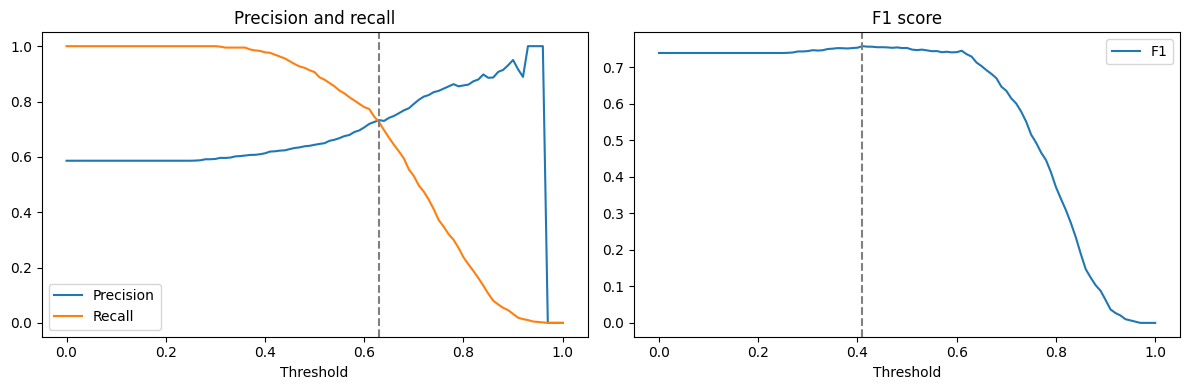

In [14]:
best_f1 = metrics.loc[metrics["f1"].idxmax()]

print(f"Q3 — threshold: {intersection['threshold']:.2f}")
print(f"Q4 — threshold: {best_f1['threshold']:.2f}")
print(f"Maximum F1: {best_f1['f1']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics["threshold"], metrics["precision"], label="Precision")
axes[0].plot(metrics["threshold"], metrics["recall"], label="Recall")
axes[0].axvline(intersection["threshold"], color="gray", linestyle="--")
axes[0].set_title("Precision and recall")
axes[0].set_xlabel("Threshold")
axes[0].legend()

axes[1].plot(metrics["threshold"], metrics["f1"], label="F1")
axes[1].axvline(best_f1["threshold"], color="gray", linestyle="--")
axes[1].set_title("F1 score")
axes[1].set_xlabel("Threshold")
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
# Questions 5-6
cv_results = []

for C in [0.000001, 0.001, 1]:
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1,
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        dv, model = train_model(fold_train, C=C)
        predictions = predict(fold_val, dv, model)

        score = roc_auc_score(fold_val[target], predictions)
        scores.append(score)

    cv_results.append({
        "C": C,
        "mean_auc": np.mean(scores),
        "std_auc": np.std(scores),
    })

cv_results = pd.DataFrame(cv_results)

print(cv_results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

q5_std = cv_results.loc[cv_results["C"] == 1, "std_auc"].iloc[0]
print(f"\nQ5 — standard deviation for C=1: {q5_std:.3f}")

ranked = cv_results.assign(
    mean_rounded=cv_results["mean_auc"].round(3),
    std_rounded=cv_results["std_auc"].round(3),
).sort_values(
    ["mean_rounded", "std_rounded", "C"],
    ascending=[False, True, True],
)

best_C = ranked.iloc[0]["C"]
print(f"Q6 — best C: {best_C:g}")

       C  mean_auc  std_auc
0.000001  0.616734 0.018670
0.001000  0.749172 0.009996
1.000000  0.731727 0.006853

Q5 — standard deviation for C=1: 0.007
Q6 — best C: 0.001
